In [4]:
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.load_tex_defs()

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate

To create your own package, have a look at the example in `course_tools` and the documentation at https://packaging.python.org/en/latest/tutorials/packaging-projects/.

The key files are
- The `pyproject.toml` file, which specifies that this is a python package
- The `src/bayesian_stats_course_tools/__init__.py`, which makes `bayesian_stats_course_tools` a python module that can be imported.

### Exercise

1. Create a new directory at the top of the JupyterLab file system
2. Create a new Python notebook

3. Obtain an estimate of the value of $\pi$
    - From the definition in `numpy`
    - Using an analytic series expansion: $\pi = 4 \sum_{k=0}^\infty \frac{(-1)^{k}}{2k + 1}$
    - Using a Monte-Carlo estimate: 
        1. Sample $n$ points uniformly on the unit square using `numpy.random.uniform`
        2. Count the number $n_{<r}$ of points with distance $r = \sqrt{x^2+y^2} \leq 1$
        3. Compare the fraction $\frac{n_{<r}}{n}$ to the ratio of the area of a quadrant of a disc to the area of the square to derive an estimate of $\pi$
    - Bonus: Repeat for (hyper) cube and (hyper) ball in 3 or more dimensions. How does the number of samples required to get a robust estimate of $\pi$ change with the number of dimensions? 

4. Use the debugger to step through some iterations of your code.

5. Create plots showing the estimated value as the number of terms in the series expansion and the number of Monte-Carlo samples is varied

In [9]:
print(np.pi)

3.141592653589793


In [28]:
def series(n):
    reihe = 0
    for k in range(n):
        reihe += 4 * (-1)**k / (2*k + 1)
    return reihe

print(series(1000))
print(series(10000))
print(series(100000))

3.140592653839794
3.1414926535900345
3.1415826535897198


In [82]:
rng = np.random.default_rng(seed=42)

def montecarlo(n):
    temp = rng.uniform(0, 1, (n, 2))
    x = temp[:,0]
    y = temp[:,1]

    r = np.sqrt(x**2 + y**2)

    kleiner1 = np.array([])

    for i in range(n):
        if r[i] <= 1:
            kleiner1 = np.append(kleiner1, r[i])

    counts = np.size(kleiner1)
    fraction = counts / n

    return fraction * 4

In [83]:
n_values = [10, 100, 1000, 10000, 100000]

series_values = []
series_errors = []

for n in n_values:
    value = series(n)
    series_values.append(value)
    series_errors.append(abs(value - np.pi))

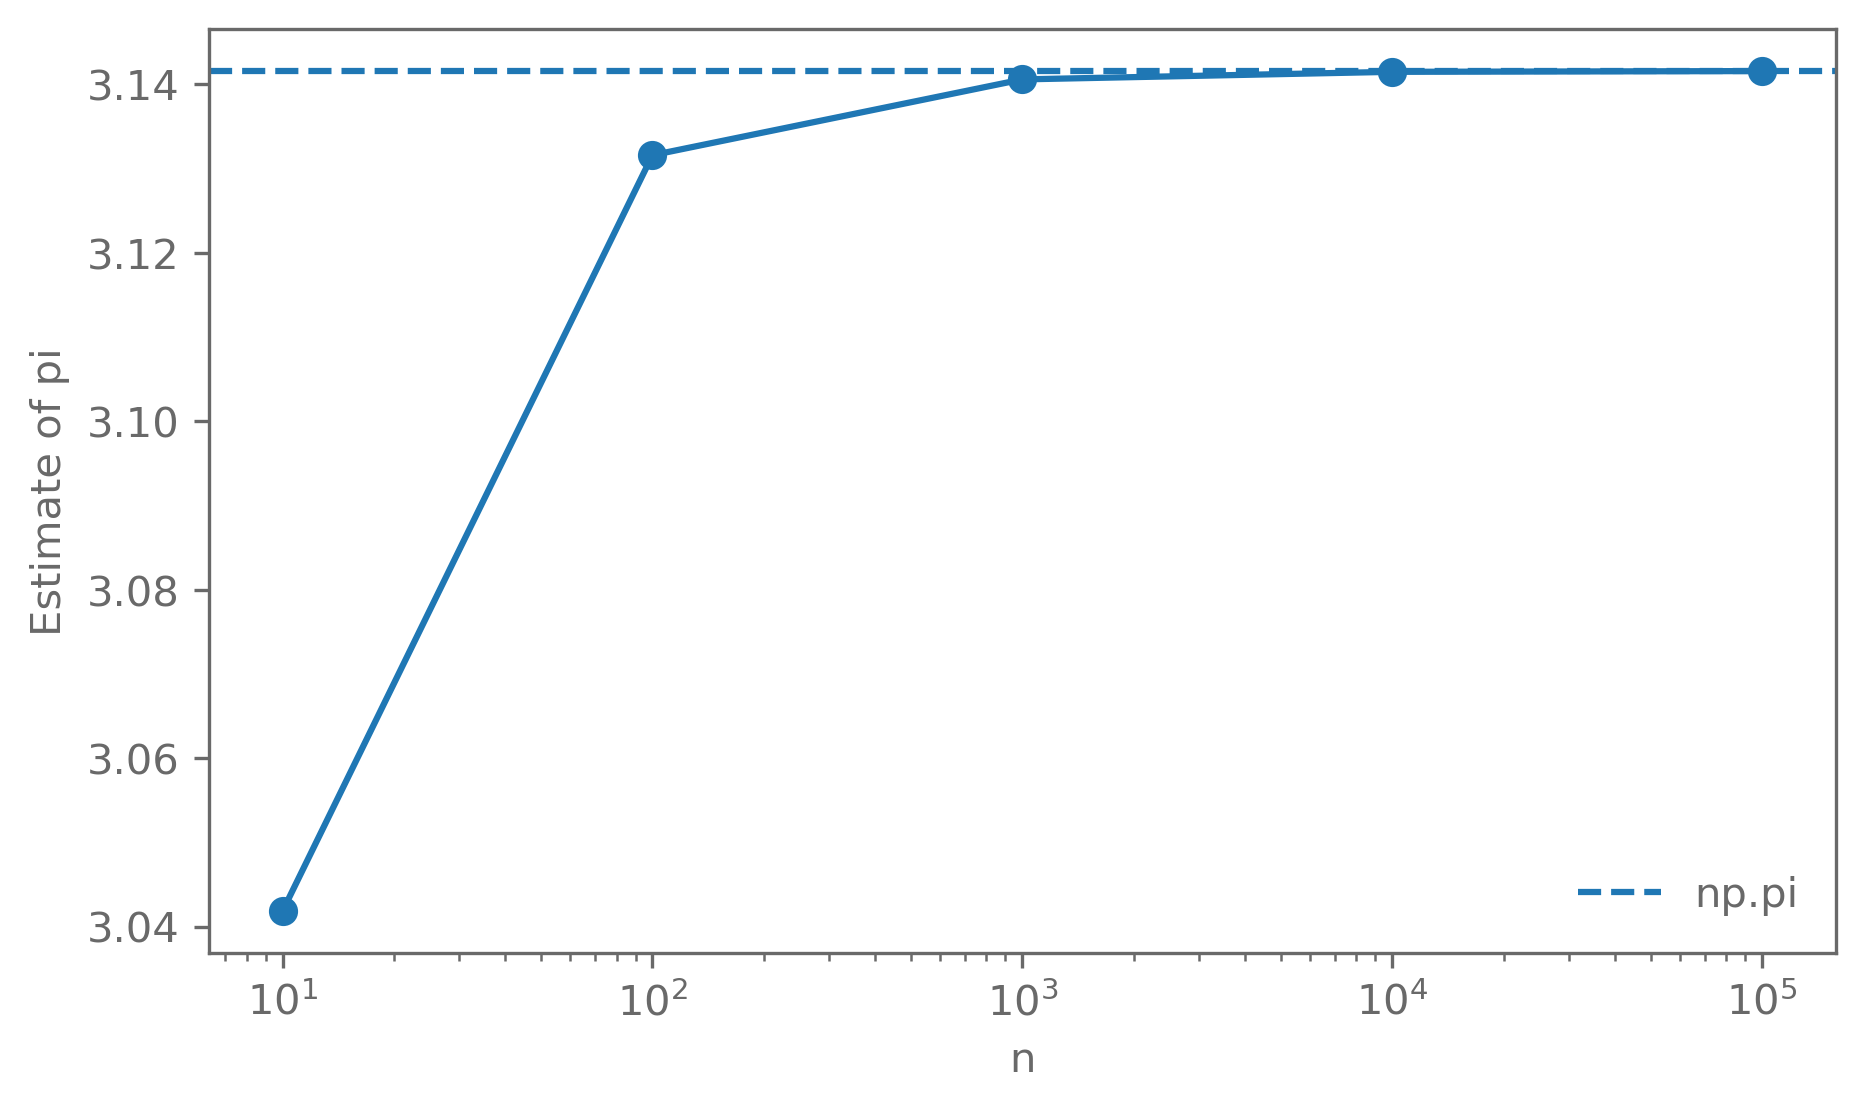

In [84]:
plt.plot(n_values, series_values, marker="o")
plt.axhline(np.pi, linestyle="--", label="np.pi")

plt.xscale("log")
plt.xlabel("n")
plt.ylabel("Estimate of pi")
plt.legend()
plt.show()

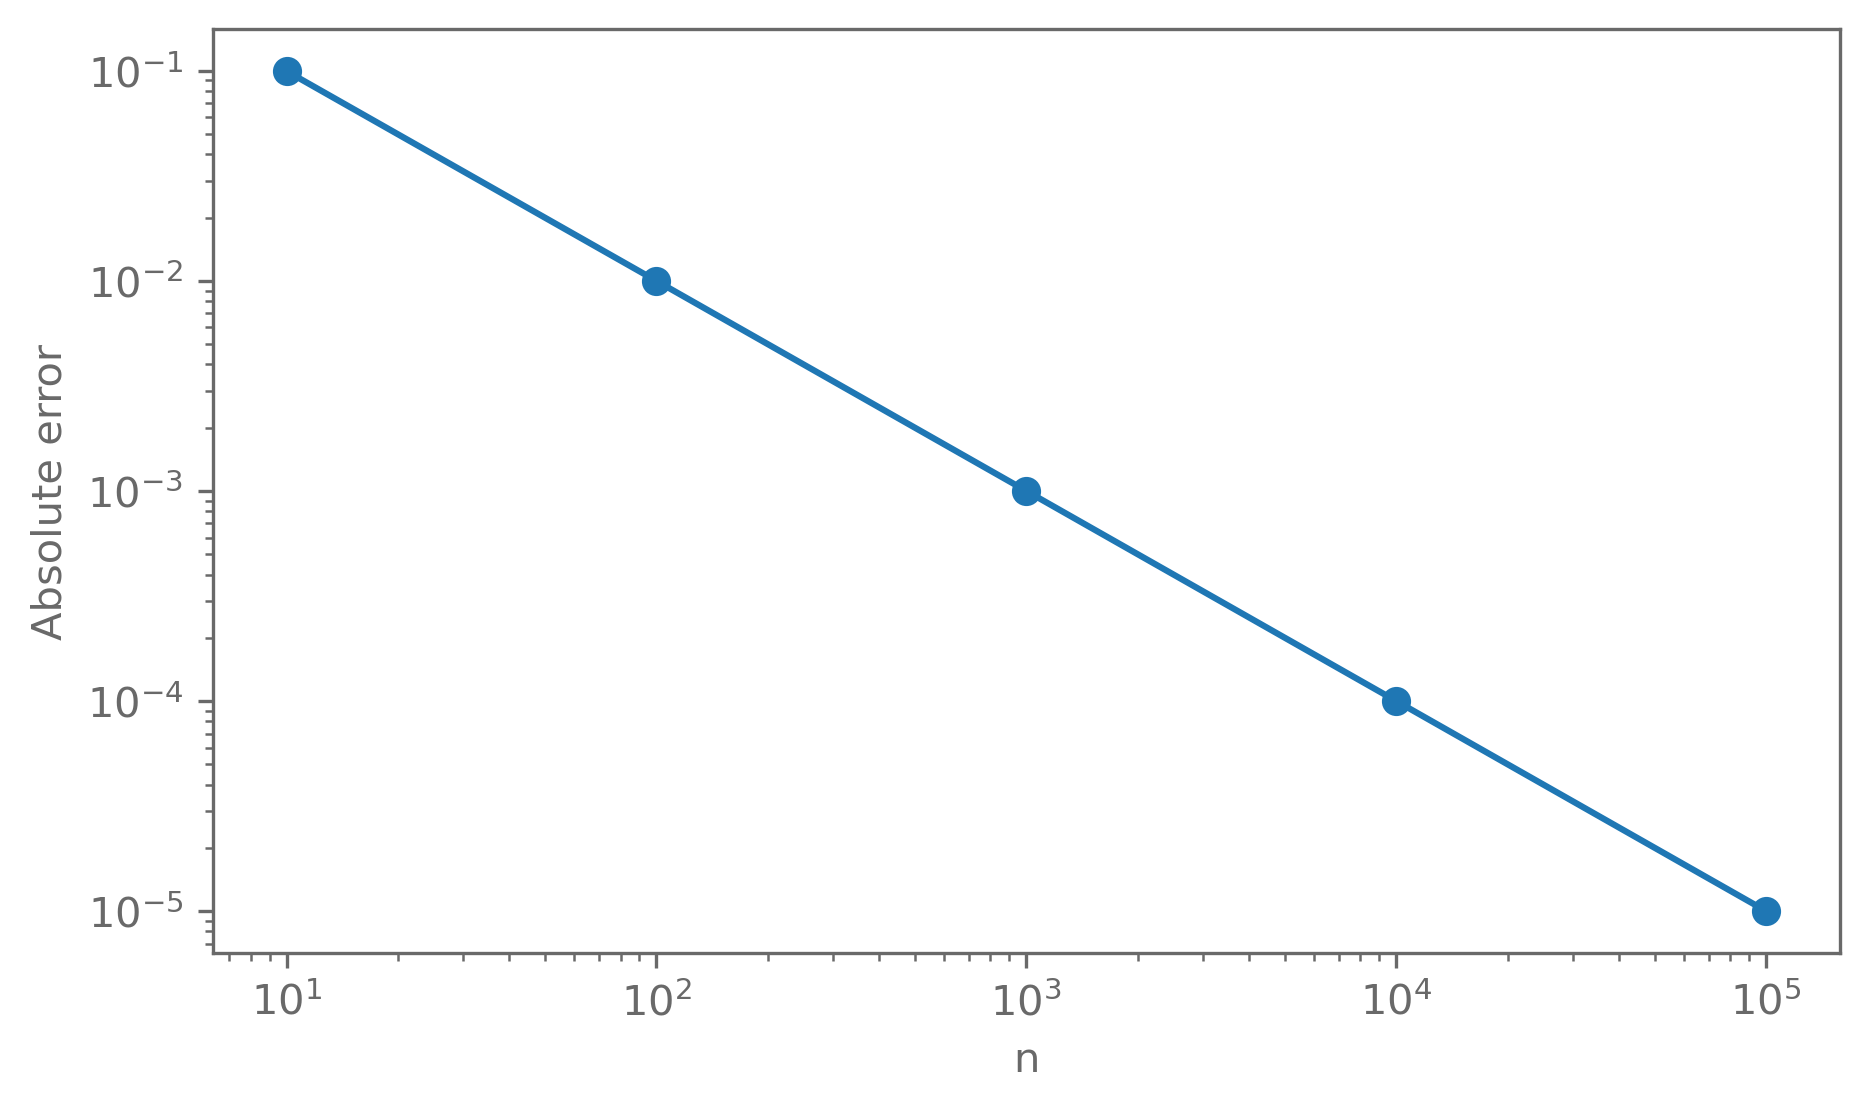

In [85]:
plt.plot(n_values, series_errors, marker="o")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("n")
plt.ylabel("Absolute error")
plt.show()

In [86]:
n_values_mc = [10, 100, 1000, 10000, 100000]

montecarlo_values = []
montecarlo_errors = []

for n in n_values_mc:
    value = montecarlo(n)
    montecarlo_values.append(value)
    montecarlo_errors.append(abs(value - np.pi))

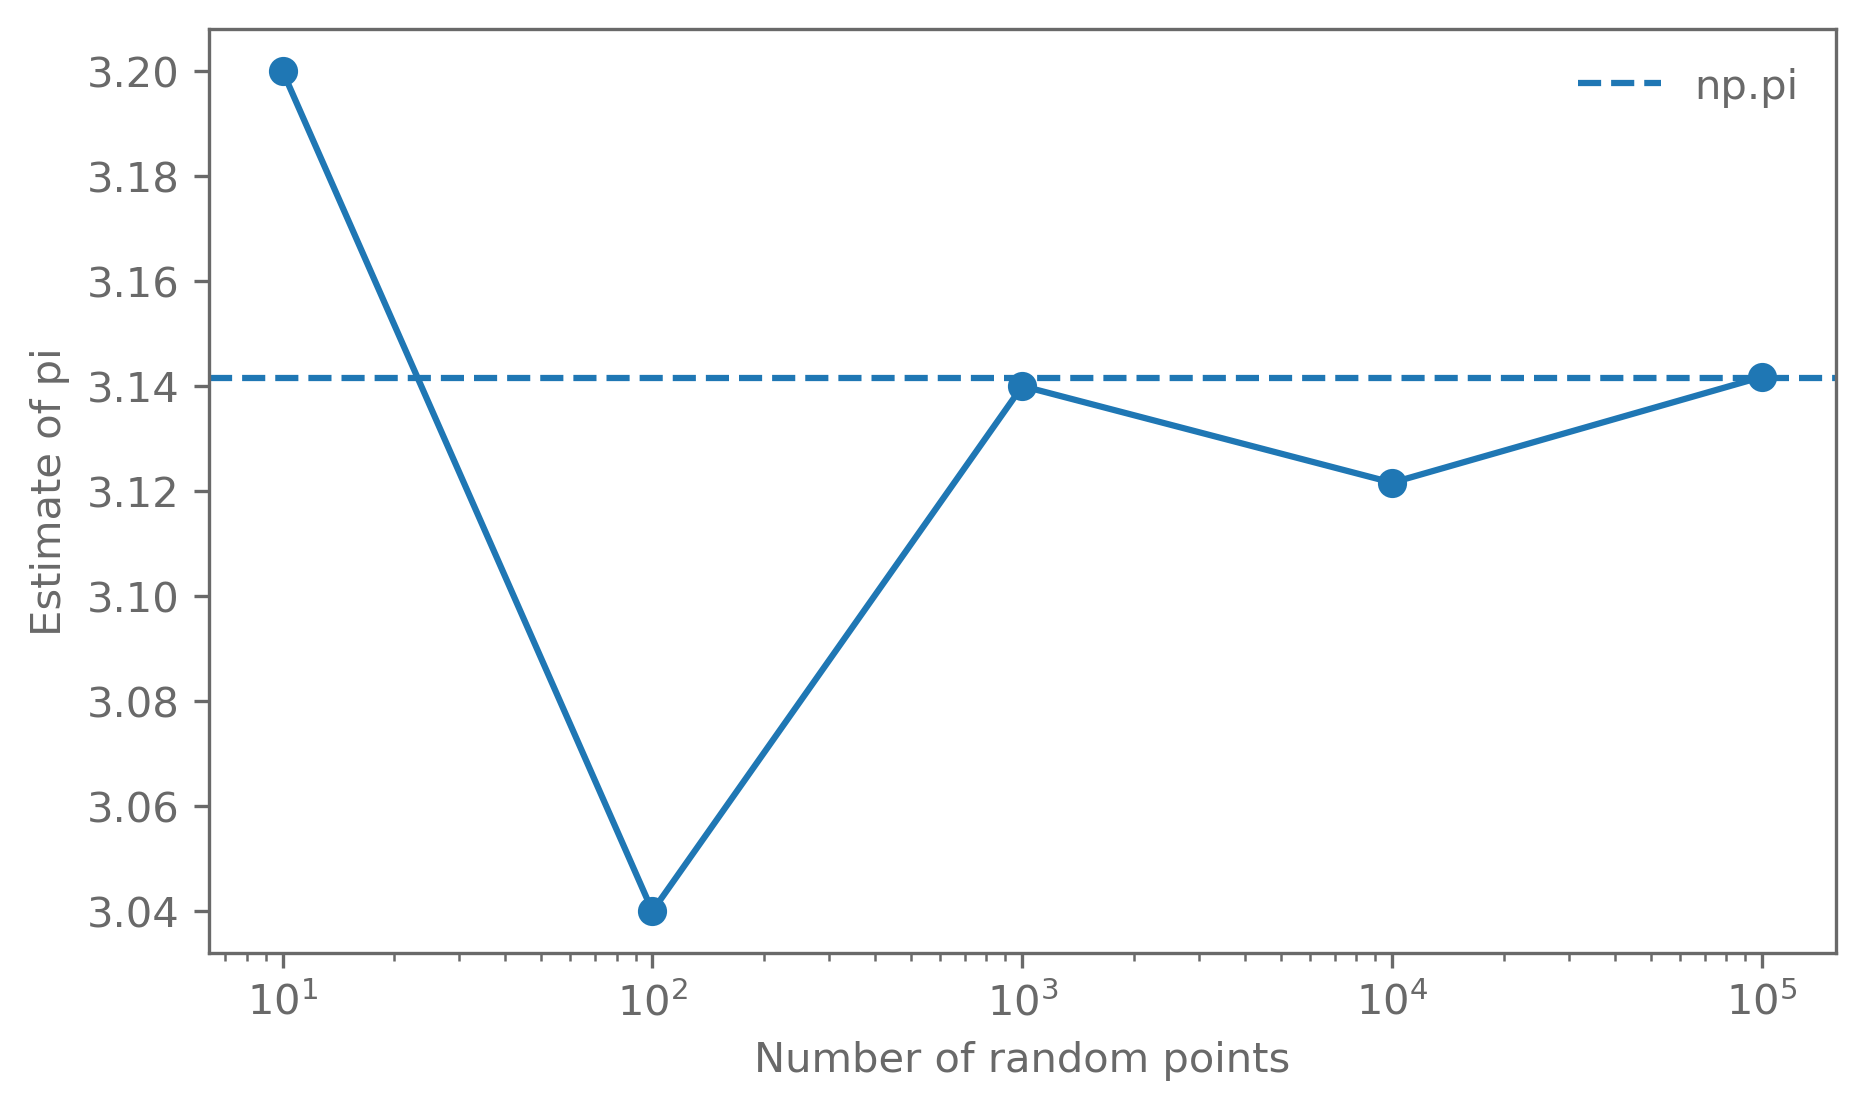

In [80]:
plt.plot(n_values_mc, montecarlo_values, marker="o")
plt.axhline(np.pi, linestyle="--", label="np.pi")

plt.xscale("log")
plt.xlabel("Number of random points")
plt.ylabel("Estimate of pi")
plt.legend()
plt.show()

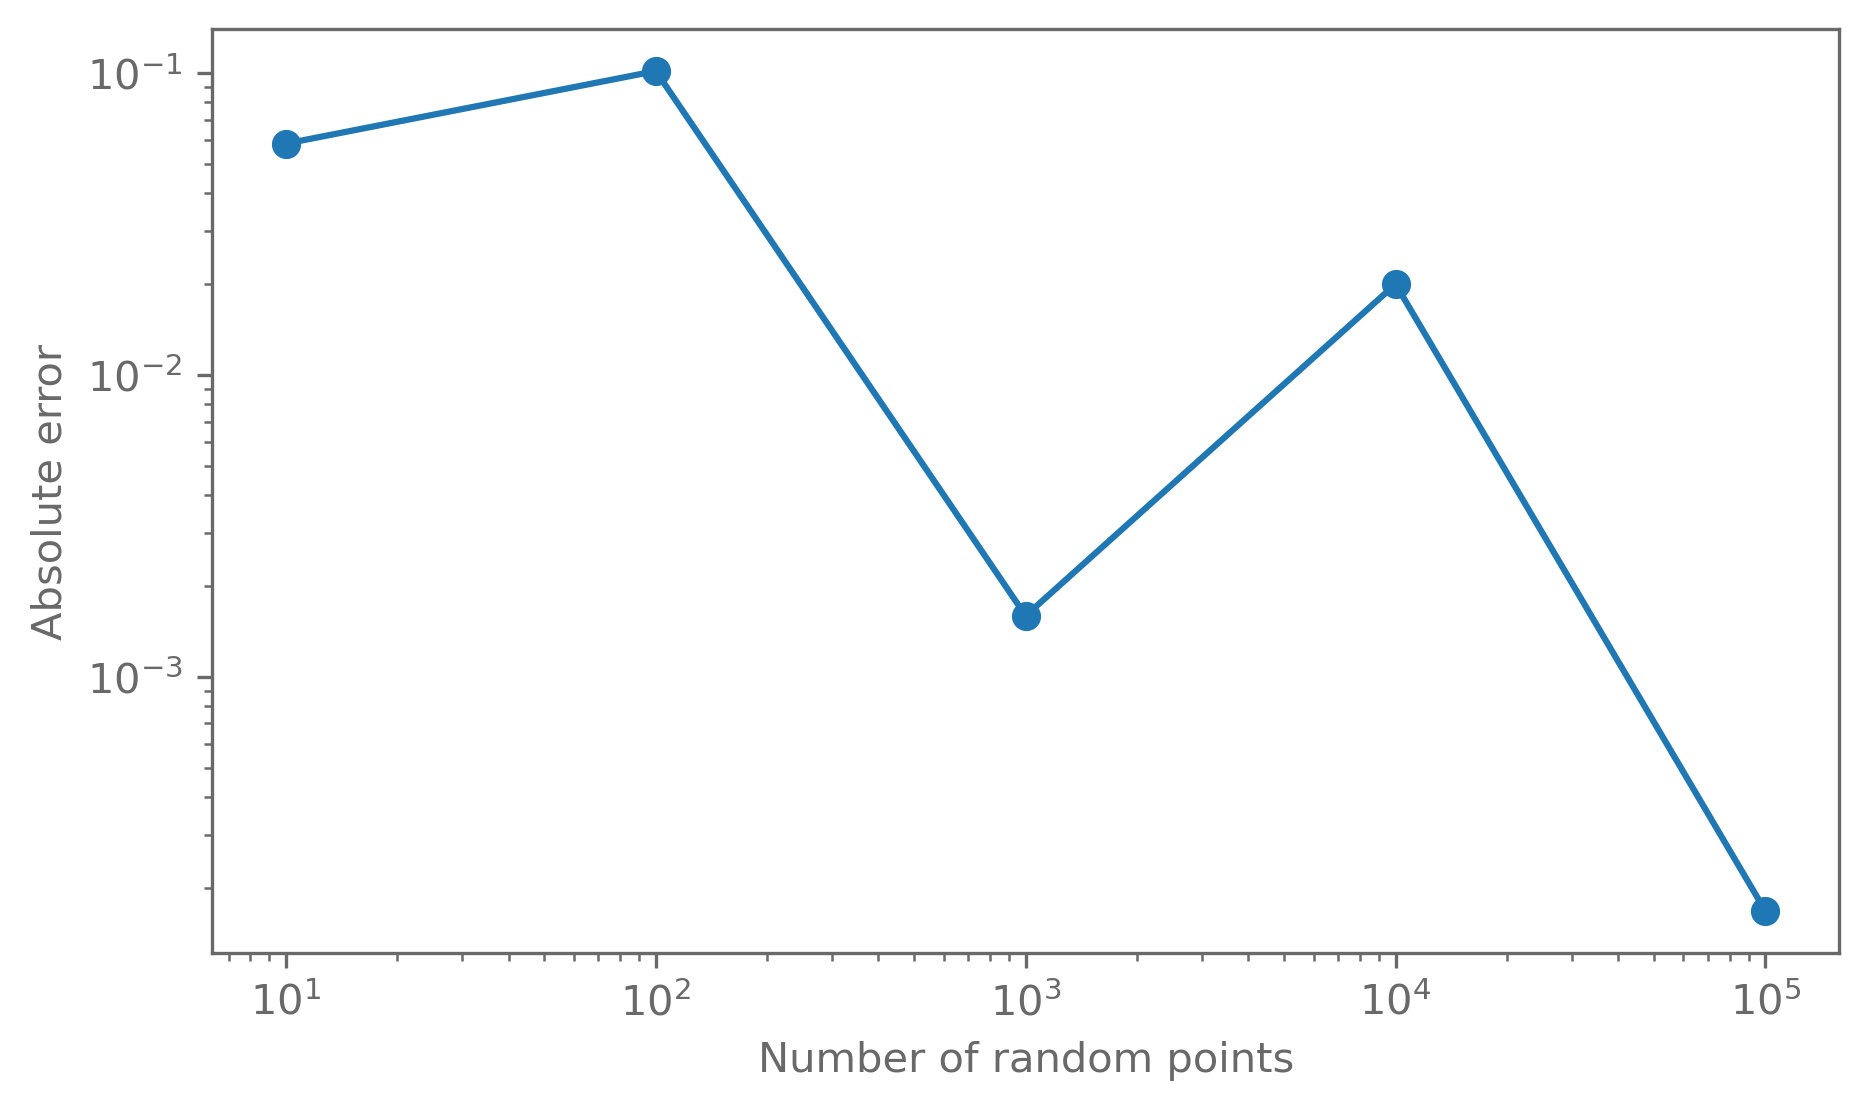

In [81]:
plt.plot(n_values_mc, montecarlo_errors, marker="o")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of random points")
plt.ylabel("Absolute error")
plt.show()